# PALLAS Campaign B — Inverse Surrogate Modeling

**Medium Objective 2 | Reproducible baseline → feature engineering → five-MLP ensemble**

**Goal:** infer four plasma-density-profile controls (`P_max`, `cN2_max`, `L_inj`, `dip_frac`) from eight electron-beam observables and the known laser focal offset (`x_of`). Only successfully injected simulations are used.

## 1. Imports and dataset location

Expected input file: `data/pallas_hackathon_data/campaign_B.parquet`, relative to the directory where Jupyter was started. Update `DATA_PATH` if necessary. The dataset contains some array-valued columns; select only the 13 scalar columns needed for modeling **before** numerical cleaning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score

DATA_PATH = Path("data/pallas_hackathon_data")
file_path = DATA_PATH / "campaign_B.parquet"
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path.resolve()} — update DATA_PATH.")

B = pd.read_parquet(file_path)
print("Raw dataset shape:", B.shape)
print("Successfully injected simulations:", int(B["injected"].sum()))

Raw dataset shape: (5286, 35)
Successfully injected simulations: 2882


## 2. Inputs, targets, cleaning, and the fixed holdout split

**Original nine inputs:** `E_med_MeV`, `dE_mad`, `q_end`, `i_peak`, `n_emit_x`, `sigma_z`, `sigma_y`, `div_rms`, `x_of`.

**Four targets:** `P_max`, `cN2_max`, `L_inj`, `dip_frac`.

The split matches the original experiment: `train_test_split(test_size=0.2, random_state=42)` on the ordered, cleaned injected-only table. Do not shuffle or sort the table before the split if you want to reproduce earlier results.

In [2]:
FEATURES = [
    "E_med_MeV", "dE_mad", "q_end", "i_peak", "n_emit_x",
    "sigma_z", "sigma_y", "div_rms", "x_of"
]
TARGETS = ["P_max", "cN2_max", "L_inj", "dip_frac"]

B_inj = B[B["injected"] == True].copy()
B_clean = B_inj[FEATURES + TARGETS].copy()
B_clean = B_clean.apply(pd.to_numeric, errors="coerce")
B_clean = B_clean.replace([np.inf, -np.inf], np.nan).dropna()

X = B_clean[FEATURES]
y = B_clean[TARGETS]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Valid injected simulations:", len(B_clean))
print("Training:", len(X_train), "| Validation:", len(X_val))
print("Input dimensions:", X_train.shape[1], "| Output dimensions:", y_train.shape[1])
assert X_train.index.intersection(X_val.index).empty

Valid injected simulations: 2882
Training: 2305 | Validation: 577
Input dimensions: 9 | Output dimensions: 4


## 3. Linear Regression baseline — original nine inputs

The baseline uses `StandardScaler` for the **inputs**, then fits one multi-output `LinearRegression` estimator. The model is evaluated on the held-out 20% validation rows using R² calculated separately for each target; the mean is the unweighted average of the four target R² values.

In [3]:
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_val)

def score_outputs(y_true, predicted, targets=TARGETS):
    scores = {
        target: r2_score(y_true[target], predicted[:, i])
        for i, target in enumerate(targets)
    }
    scores["mean"] = np.mean([scores[target] for target in targets])
    return scores

linear_scores = score_outputs(y_val, linear_pred)
print("Linear Regression baseline (R²):")
display(pd.Series(linear_scores).round(4).to_frame("R²"))

Linear Regression baseline (R²):


,R²
P_max,0.7728
cN2_max,0.7367
L_inj,0.5314
dip_frac,0.0237
mean,0.5161


## 4. Add two engineered input features

Retain the nine original observables, then add:

1. `charge_current_ratio = q_end / i_peak`: a proxy for a characteristic charge/current timescale (check units; not necessarily the RMS bunch duration).
2. `relative_energy_spread = dE_mad / E_med_MeV`: a dimensionless relative energy-spread descriptor, assuming the energy columns have compatible units.

These are **empirical features** derived solely from the available input observables. They introduce no information from the four targets. We previously tested `sigma_y / n_emit_x` and `n_emit_x / div_rms` but **did not retain either** because they reduced validation accuracy.

We use a small numerical floor only to guard against division by zero. A true zero or unexpectedly tiny denominator should be examined; the finite-value assertion prevents silent downstream failures.

In [4]:
def add_engineered_features(frame):
    result = frame.copy()
    eps = 1e-12
    result["charge_current_ratio"] = result["q_end"] / (result["i_peak"] + eps)
    result["relative_energy_spread"] = result["dE_mad"] / (result["E_med_MeV"] + eps)
    return result

X_train_11 = add_engineered_features(X_train)
X_val_11 = add_engineered_features(X_val)

assert X_train_11.columns.tolist() == X_val_11.columns.tolist()
assert X_train_11.shape[1] == 11
assert np.isfinite(X_train_11.to_numpy()).all()
assert np.isfinite(X_val_11.to_numpy()).all()
print("Number of engineered + original input features:", X_train_11.shape[1])
print(X_train_11.columns.tolist())

Number of engineered + original input features: 11
['E_med_MeV', 'dE_mad', 'q_end', 'i_peak', 'n_emit_x', 'sigma_z', 'sigma_y', 'div_rms', 'x_of', 'charge_current_ratio', 'relative_energy_spread']


## 5. Log transform four skewed original observables

Our input-distribution analysis showed substantial right skewness in `n_emit_x`, `dE_mad`, `div_rms`, and `sigma_z`. Apply a natural logarithm to these four **original** columns in both train and validation sets. The two engineered ratios remain calculated from the original values, matching our best previously evaluated setup.

The log is a deterministic per-row transformation: it learns no distributional parameters. We then let the MLP pipeline fit its `StandardScaler` **only on training rows**. The positive-value checks are deliberate: do not silently take a log of nonpositive physical observables.

In [5]:
LOG_FEATURES = ["n_emit_x", "dE_mad", "div_rms", "sigma_z"]

def apply_log_transforms(frame):
    result = frame.copy()
    for col in LOG_FEATURES:
        if not (result[col] > 0).all():
            raise ValueError(f"Feature {col} contains nonpositive values; log undefined.")
        result[col] = np.log(result[col])
    return result

X_train_final = apply_log_transforms(X_train_11)
X_val_final = apply_log_transforms(X_val_11)

assert np.isfinite(X_train_final.to_numpy()).all()
assert np.isfinite(X_val_final.to_numpy()).all()
print("Final input shape:", X_train_final.shape)
print("Log-transformed:", LOG_FEATURES)

Final input shape: (2305, 11)
Log-transformed: ['n_emit_x', 'dE_mad', 'div_rms', 'sigma_z']


## 6. Final architecture: five MLP regressors with averaged predictions

Each model predicts the **four targets simultaneously**, preserving shared information. Input and output scaling are learned only from the training set via the pipeline and `TransformedTargetRegressor`.

**Architecture:** `(256, 128, 64)`; activation `tanh`, optimizer `adam`, learning rate `0.0005`, L2 regularization (`alpha`) `0.001`; maximum `700` epochs; early stopping on an internal 15% split with `n_iter_no_change=40`. We use exactly five independent seeds: `10, 21, 42, 73, 100`.

The five prediction arrays are averaged **in original target units**. With `TransformedTargetRegressor`, `predict` already undoes target standardization automatically.

In [6]:
def build_mlp(seed):
    return TransformedTargetRegressor(
        regressor=make_pipeline(
            StandardScaler(),
            MLPRegressor(
                hidden_layer_sizes=(256, 128, 64),
                activation="tanh",
                solver="adam",
                learning_rate_init=0.0005,
                alpha=0.001,
                max_iter=700,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=40,
                random_state=seed,
            )
        ),
        transformer=StandardScaler(),
    )

SEEDS = [10, 21, 42, 73, 100]
ensemble_models = []
ensemble_predictions = []

for seed in SEEDS:
    model = build_mlp(seed)
    model.fit(X_train_final, y_train)
    prediction = model.predict(X_val_final)
    ensemble_models.append(model)
    ensemble_predictions.append(prediction)
    print(f"Seed {seed} completed; dip_frac R² = {r2_score(y_val['dip_frac'], prediction[:, 3]):.4f}")

ensemble_pred = np.mean(np.stack(ensemble_predictions, axis=0), axis=0)
ensemble_scores = score_outputs(y_val, ensemble_pred)
print("Five-MLP ensemble training completed.")

Seed 10 completed; dip_frac R² = 0.7873
Seed 21 completed; dip_frac R² = 0.7742
Seed 42 completed; dip_frac R² = 0.7745
Seed 73 completed; dip_frac R² = 0.7856
Seed 100 completed; dip_frac R² = 0.7920
Five-MLP ensemble training completed.


## 7. Final model comparison

In [7]:
comparison = pd.DataFrame({
    "Linear Regression (9 inputs)": linear_scores,
    "5-MLP ensemble (11 inputs + logs)": ensemble_scores,
})
display(comparison.round(4))
print("Mean ensemble R²:", round(ensemble_scores["mean"], 4))
print("Ensemble dip_frac R²:", round(ensemble_scores["dip_frac"], 4))

,Linear Regression (9 inputs),5-MLP ensemble (11 inputs + logs)
P_max,0.7728,0.9746
cN2_max,0.7367,0.9667
L_inj,0.5314,0.9534
dip_frac,0.0237,0.8017
mean,0.5161,0.9241


Mean ensemble R²: 0.9241
Ensemble dip_frac R²: 0.8017


## 8. Diagnostic visualization — dip fraction

Plot predicted versus simulated `dip_frac` and calculate its absolute error. This can reveal regression to the mean and large outliers that are not obvious from R² alone.

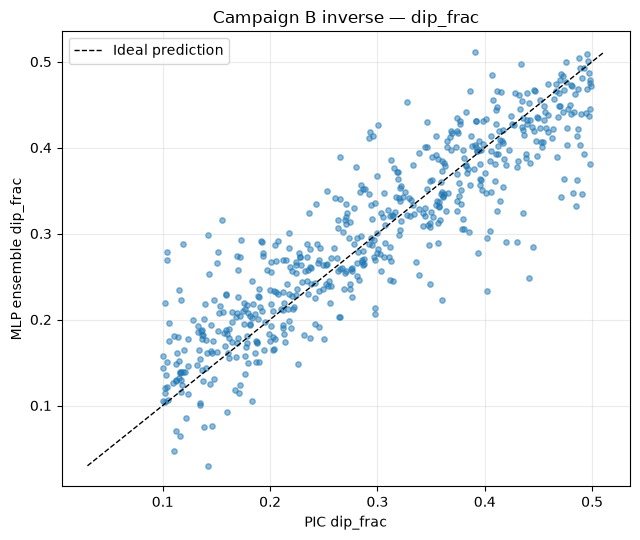

dip_frac R² = 0.8017; MAE = 0.0389


In [8]:
dip_true = y_val["dip_frac"].to_numpy()
dip_pred = ensemble_pred[:, TARGETS.index("dip_frac")]
dip_mae = np.mean(np.abs(dip_true - dip_pred))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(dip_true, dip_pred, alpha=0.5, s=15)
limits = [min(dip_true.min(), dip_pred.min()), max(dip_true.max(), dip_pred.max())]
ax.plot(limits, limits, "k--", linewidth=1, label="Ideal prediction")
ax.set(xlabel="PIC dip_frac", ylabel="MLP ensemble dip_frac", title="Campaign B inverse — dip_frac")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"dip_frac R² = {ensemble_scores['dip_frac']:.4f}; MAE = {dip_mae:.4f}")